In [ ]:
SECTION 1: Generate a regional MOM6 domain

In [ ]:
Step 1.1: Horizontal Grid

In [20]:
from CrocoDash.grid import Grid

grid = Grid(
  resolution = 1/8, # in degrees
  xstart = 260, # min longitude in [0, 360]
  lenx = 60.0, # longitude extent in degrees
  ystart = 5.0, # min latitude in [-90, 90]
  leny = 35.0, # latitude extent in degrees
  name = "gomcar",
)

In [2]:
Step 1.2: Topography

SyntaxError: invalid syntax (3271835214.py, line 1)

In [22]:
from CrocoDash.topo import Topo

topo = Topo(
    grid = grid,
    min_depth = 9.5, # in meters
)

In [23]:
from pathlib import Path

bathymetry_path= Path("/glade/campaign/cgd/oce/projects/CROCODILE/workshops/2026/CrocoDash/data/gebco_2026/GEBCO_2026_coarse_x8.nc")
# The GEBCO bathymetry path on Derecho is: /glade/campaign/cgd/oce/projects/CROCODILE/workshops/2026/CrocoDash/data/gebco_2026/GEBCO_2026.nc

if not bathymetry_path.exists():
    raise FileNotFoundError("Bathymetry file not found, please replace with path to bathymetry file")

topo.set_from_dataset(
    bathymetry_path = bathymetry_path,
    longitude_coordinate_name="lon",
    latitude_coordinate_name="lat",
    vertical_coordinate_name="elevation",
    depth_method = "xesmf",
    mask_method = "dataset"
)

Slicing source bathymetry to domain: (260.0, 320.0) x (5.0, 40.0) with buffer 0.5
  Resolution Diagnostics

  Source dataset (GEBCO_2026_coarse_x8.nc):
    dlon = 120.0 arcsec  (0.033333°)
    dlat = 120.0 arcsec  (0.033333°)
    dx   ~ 3695 m)
    dy   ~ 3706 m

  Model grid (T-cell spacing):
    median = 13.36 km
    min    = 12.17 km
    max    = 13.87 km

  Resolution ratio (model dx / dataset dx):
    median = 3.6x
    max    = 3.8x

  Cressman / stats-mask threshold: 12x
  → RECOMMENDED: direct_xesmf_regrid()  (bilinear / conservative)
    Ratio 3.6x is below the threshold where Cressman
    likely provides benefit over xesmf regridding.
**NOTE**
            If bathymetry setup fails (e.g. kernel crashes), restart the kernel and edit this cell.
            Call ``[topo_object_name].mpi_set_depth_from_xesmf()`` instead. Follow the given instructions for using mpi
            and ESMF_Regrid outside of a python environment. This breaks up the process, so be sure to call
           

/glade/work/shanru/conda-envs/CrocoDash/lib/python3.11/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not F_CONTIGUOUS. ' 'Will affect performance.')


Warning! This was an opionated workflow function that ran multiple steps in sequence. Please edit the mask manually if need be (Some depth methods, like cressman, are mask-aware and may need to be rerun)! 


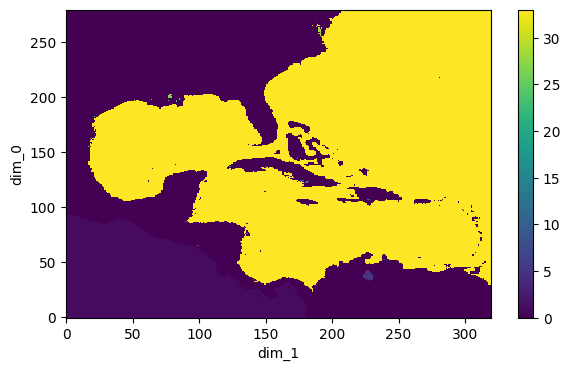

In [13]:
topo.basintmask.plot(size=4, aspect = grid.nx / grid.ny)

The manual mask is not initialized. Initializing it now from the depth raw mask


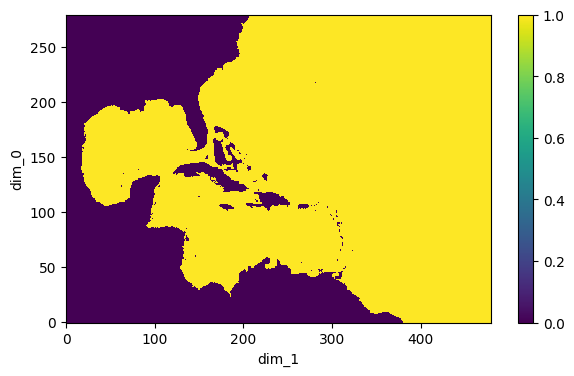

In [24]:
topo.keep_largest_basin()
topo.basintmask.plot(size=4, aspect = grid.nx / grid.ny)

In [26]:
## Optionally, uncomment the below lines to further modify the topography interactively
%matplotlib ipympl
from CrocoDash.topo_editor import TopoEditor
TopoEditor(topo)

TopoEditor(children=(VBox(children=(HTML(value='<h2>Topo Editor</h2>'), VBox(children=(VBox(children=(HTML(val…

In [ ]:
Step 1.3: Vertical Grid

In [27]:
from CrocoDash.vgrid import VGrid

vgrid  = VGrid.hyperbolic(
    nk = 32, # number of vertical levels
    depth = topo.max_depth,
    ratio=50.0 # target ratio of top to bottom layer thicknesses
)

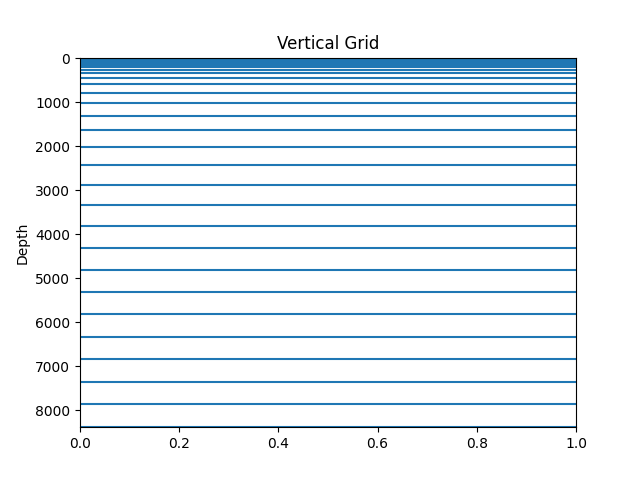

In [28]:
import matplotlib.pyplot as plt
plt.close()
# Create the plot
for depth in vgrid.zi:
    plt.axhline(y=depth, linestyle='-')  # Horizontal lines

plt.ylim(max(vgrid.zi) + 10, min(vgrid.zi) - 10)  # Invert y-axis so deeper values go down
plt.ylabel("Depth")
plt.title("Vertical Grid")
plt.show()

In [ ]:
SECTION 2: Create the CESM case

In [ ]:
Step 2.1: Specify case name and directories

In [29]:
from pathlib import Path

# CESM case (experiment) name
casename = "hurcn_gomcar_ocn_wav.001"

# CESM source root (Update this path accordingly!!!)
cesmroot ="/glade/work/shanru/crocodile2026/CESM"

# Place where all your input files go 
inputdir = Path("/glade/work/shanru/crocodile2026/croc_input") / casename
    
# CESM case directory
caseroot = Path("/glade/work/shanru/crocodile2026/croc_cases") / casename

In [ ]:
Step 2.2: Create the Case

In [30]:
from CrocoDash.case import Case

case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'UCGD0009', # Enter Project ID for PBS Queue
    #job_queue = "tutorial", # PBS queue the run is submitted to
    job_wallclock_time = "01:00:00", # hh:mm:ss walltime requested for the run
    override = True,
    machine = "derecho",
    compset = "CWR_JRA"
)

WARNING [CIME.XML.grids] Schema validity test fails for /glade/work/shanru/crocodile2026/CESM/ccs_config/config_grids_nuopc.xml


Creating case...

Running the create_newcase tool with the following command:

/glade/work/shanru/crocodile2026/CESM/cime/scripts/create_newcase --compset CWR_JRA --res USER_RES --case /glade/work/shanru/crocodile2026/croc_cases/hurcn_gomcar_ocn_wav.001 --machine derecho --run-unsupported --handle-preexisting-dirs a --pecount L --project UCGD0009 --non-local 

The create_newcase command was successful.

• Updating case xml variables to include newly generated ocean grid "gomcar" with the following properties:
 nx: 480, ny: 280. ocean mesh: /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/ocn/ESMF_mesh_gomcar_9b2198.nc.

./xmlchange OCN_GRID=gomcar --non-local
./xmlchange OCN_NX=480 --non-local
./xmlchange OCN_NY=280 --non-local
./xmlchange OCN_DOMAIN_MESH=/glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/ocn/ESMF_mesh_gomcar_9b2198.nc --non-local
./xmlchange ICE_GRID=gomcar --non-local
./xmlchange ICE_NX=480 --non-local
./xmlchange ICE_NY=280 --no

In [ ]:
Section 3: Prepare ocean and wave forcing data

In [ ]:
Step 3.1 Configure Initial Conditions and Forcings

In [36]:
case.configure_forcings(
    date_range = ["2020-08-19 00:00:00", "2020-09-01 00:00:00"],
    boundaries=["south","north","east"],
    product_name = "GLORYS",
    function_name="get_glorys_data_from_rda",
    ww3_obc_product_name='CESM-WW3-JRA',
    ww3_obc_function_name="get_cesm_ww3_jra_spectra",        
)

INFO [CrocoDash.forcing.base] [REQUIRED] Activating StreamYears
INFO [CrocoDash.forcing.base] [SKIP] BGC incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] BGCIC incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] BGCIronForcing incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] BGCRiverNutrients incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] Chl missing args: ['chl_processed_filepath']
INFO [CrocoDash.forcing.base] [SKIP] CICE incompatible with compset
INFO [CrocoDash.forcing.base] [REQUIRED] Activating conditions
INFO [CrocoDash.forcing.base] [SKIP] Runoff incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']
INFO [CrocoDash.forcing.base] [REQUIRED] Activating WW3
INFO [CrocoDash.forcing.base] Configuring StreamYears


WARNING [CrocoDash.forcing.atm] DROF stream years left at CESM defaults: no active drof


Adding parameter changes to user_nl_datm_streams:

  ! Align CORE_IAF_JRA_1p5_2023 streams with the run dates (CrocoDash: CDEPS defaults to year_align=1)
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:year_first = 2018
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:year_last = 2021
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:year_align = 2018
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:datafiles = /glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.2018.210504.nc,/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.2019.210504.nc,/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.2020.210504.nc,/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.2021.220505.nc
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:year_first = 2018
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:year_last = 2021
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:year_align = 2018
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:datafiles = /glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1

In [ ]:
Step 3.3: Process forcing data

In [37]:
case.process_forcings()

INFO [CrocoDash.forcing.obc] No bathymetry_path given; using full supergrid bounding boxes.
INFO [CrocoDash.forcing.obc] GET [south]: 2020-08-19 → 2020-09-01
INFO [CrocoDash.forcing.obc] GET [north]: 2020-08-19 → 2020-09-01
INFO [CrocoDash.forcing.obc] GET [east]: 2020-08-19 → 2020-09-01
INFO [CrocoDash.forcing.obc] REGRID [south]: None-day slices
INFO [CrocoDash.forcing.obc] PROC [0] - REGRID [south]: Spun up new proc
INFO [CrocoDash.forcing.obc] PROC [0] - REGRID [south]: Chunk start - end date: [2020-08-19] - [2020-09-01]
INFO [CrocoDash.forcing.obc] PROC [0] - REGRID [south]: Selecting raw files
INFO [CrocoDash.forcing.obc] PROC [0] - REGRID [south]: Performing regrid
INFO [CrocoDash.forcing.obc] PROC [0] - REGRID [south]: Regridding done for /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/extract_forcings/ww3/regridded_data/forcing_obc_segment_001_2020-08-19_2020-09-01.nc
INFO [CrocoDash.forcing.obc] REGRID [north]: None-day slices
INFO [CrocoDash.forcing.obc]

WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array u, assuming it's in the correct units
WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array v, assuming it's in the correct units
WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array temp, assuming it's in the correct units


Setting up Initial Conditions
Regridding Velocities... Done.
Regridding Tracers... Done.
Regridding Free surface... Done.
Saving outputs... 

WARNING [regional_mom6.validate] eta_t does not have a coordinates attribute
WARNING [regional_mom6.validate] Variable eta_t does not have 4 dimensions
WARNING [regional_mom6.validate] temp does not have a coordinates attribute
WARNING [regional_mom6.validate] Variable temp does not have 4 dimensions
WARNING [regional_mom6.validate] salt does not have a coordinates attribute
WARNING [regional_mom6.validate] Variable salt does not have 4 dimensions
WARNING [regional_mom6.validate] u does not have a coordinates attribute
WARNING [regional_mom6.validate] Variable u does not have 4 dimensions
WARNING [regional_mom6.validate] v does not have a coordinates attribute
WARNING [regional_mom6.validate] Variable v does not have 4 dimensions


INFO [CrocoDash.forcing.mom6] Start mom6_forge fill...
INFO [CrocoDash.forcing.mom6] ...end mom6_forge fill.
INFO [CrocoDash.forcing.ic] Successfully retrieved GLORYS initial condition data located in /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/ocn directory.
INFO [CrocoDash.forcing.obc] Using tmask-derived bounding boxes for OBC data download.
INFO [CrocoDash.forcing.obc] GET [south]: 2020-08-19 → 2020-09-01
INFO [GLORYS] Downloading Glorys data from RDA to /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/extract_forcings/raw_data/south_unprocessed.2020-08-19_2020-08-25.nc
INFO [GLORYS] Download of /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/extract_forcings/raw_data/south_unprocessed.2020-08-19_2020-08-25.nc complete.
INFO [GLORYS] Downloading Glorys data from RDA to /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/extract_forcings/raw_data/south_unprocessed.2020-08-26_2020-09-01.nc
INFO [GLORYS

WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array temp, assuming it's in the correct units
WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array u, assuming it's in the correct units
WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array v, assuming it's in the correct units


... (7 outputs left out)

WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array temp, assuming it's in the correct units
WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array u, assuming it's in the correct units
WARNING [regional_mom6.utils] regional_mom6 could not use pint for data array v, assuming it's in the correct units


No arakawa_grid provided, assuming the variable mapping for your data product is already in correct format.
Arakawa A grid detected in variable mapping


WARNING [regional_mom6.validate] temp_segment_003 does not have a coordinates attribute
WARNING [regional_mom6.validate] salt_segment_003 does not have a coordinates attribute
WARNING [regional_mom6.validate] u_segment_003 does not have a coordinates attribute
WARNING [regional_mom6.validate] v_segment_003 does not have a coordinates attribute
WARNING [regional_mom6.validate] eta_segment_003 does not have a coordinates attribute


INFO [CrocoDash.forcing.obc] PROC [0] - REGRID [east]: Regridding done for /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/extract_forcings/regridded_data/forcing_obc_segment_003_2020-08-19_2020-09-01.nc
INFO [CrocoDash.forcing.obc] MERGE [south]
INFO [CrocoDash.forcing.obc] Saved merged boundary at /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/ocn/forcing_obc_segment_001.nc
INFO [CrocoDash.forcing.obc] MERGE [north]
INFO [CrocoDash.forcing.obc] Saved merged boundary at /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/ocn/forcing_obc_segment_002.nc
INFO [CrocoDash.forcing.obc] MERGE [east]
INFO [CrocoDash.forcing.obc] Saved merged boundary at /glade/work/shanru/crocodile2026/croc_input/hurcn_gomcar_ocn_wav.001/ocn/forcing_obc_segment_003.nc
INFO [CrocoDash.forcing.obc] OBC processing complete.
[timing] ww3: 76.9s  ic: 60.4s  bc: 359.3s  total: 496.6s
Case is ready to be built: /glade/work/shanru/crocodile2026/croc_cases/hu

In [ ]:
Section 4: Build and run the case

In [ ]:
ssh derecho
/glade/u/home/shanru/work/crocodile2026/croc_cases/hurcn_gomcar_ocn_wav.001
qcmd -A UCGD0009 -- ./case.build
./case.submit

#
./xmlquery JOB_QUEUE
./xmlchange JOB_QUEUE=tutorial --force
qdel 7658319
